In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

uploaded = files.upload()

csv_file = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv
Dataset loaded successfully!
Shape: (111, 60)


In [ ]:

print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


First 5 rows:


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68



Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111 entries, 0 to 110
Data columns (total 60 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Country  103 non-null    object
 1   1965     103 non-null    object
 2   1966     103 non-null    object
 3   1967     103 non-null    object
 4   1968     103 non-null    object
 5   1969     103 non-null    object
 6   1970     103 non-null    object
 7   1971     103 non-null    object
 8  

In [ ]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())


Missing values in each column:
Country    8
1965       8
1966       8
1967       8
1968       8
1969       8
1970       8
1971       8
1972       8
1973       8
1974       8
1975       8
1976       8
1977       8
1978       8
1979       8
1980       8
1981       8
1982       8
1983       8
1984       8
1985       8
1986       8
1987       8
1988       8
1989       8
1990       8
1991       8
1992       8
1993       8
1994       8
1995       8
1996       8
1997       8
1998       8
1999       8
2000       8
2001       8
2002       8
2003       8
2004       8
2005       8
2006       8
2007       8
2008       8
2009       8
2010       8
2011       8
2012       8
2013       8
2014       8
2015       8
2016       8
2017       8
2018       8
2019       8
2020       8
2021       8
2022       8
2023       8
dtype: int64

Duplicate records: 7


In [ ]:

# Select country
country_name = "India"

data = df[df["Country"] == country_name].copy()

if data.empty:
    raise ValueError("Country not found. Check df['Country'].unique()")

# Convert year columns into rows
data = data.melt(
    id_vars=["Country"],
    var_name="year",
    value_name="primary_energy_consumption"
)

# Convert columns to numeric
data["year"] = pd.to_numeric(data["year"], errors="coerce")
data["primary_energy_consumption"] = pd.to_numeric(
    data["primary_energy_consumption"], errors="coerce"
)

# Sort years chronologically
data = data.sort_values("year")

# Remove missing values
data = data.dropna(
    subset=["year", "primary_energy_consumption"]
)

data["year"] = data["year"].astype(int)

print("Selected country:", country_name)
print("Total records:", len(data))
display(data.head(10))


Selected country: India
Total records: 59


,Country,year,primary_energy_consumption
0,India,1965,2.23
1,India,1966,2.30
2,India,1967,2.37
3,India,1968,2.53
4,India,1969,2.81
5,India,1970,2.75
6,India,1971,2.86
7,India,1972,3.01
8,India,1973,3.07
9,India,1974,3.25


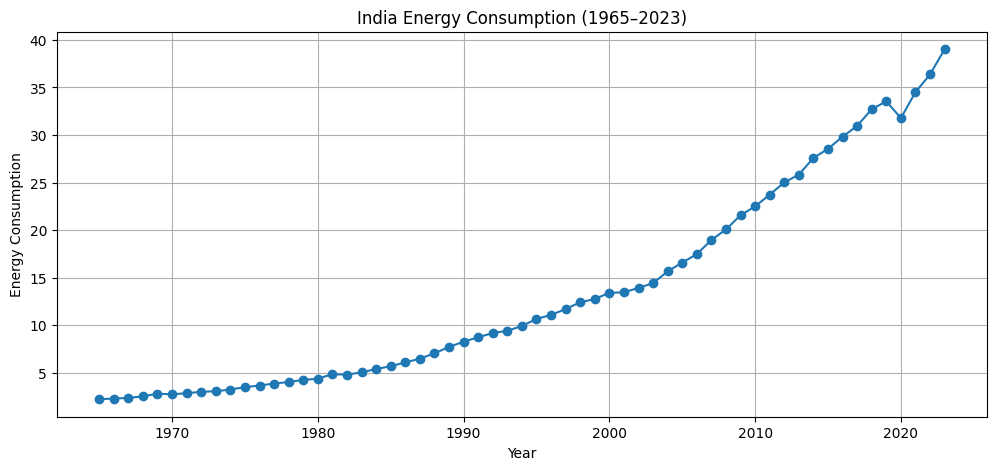

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    data["year"],
    data["primary_energy_consumption"],
    marker="o"
)

plt.title("India Energy Consumption (1965–2023)")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.grid(True)
plt.show()


In [ ]:

values = data[["primary_energy_consumption"]].values

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_values = scaler.fit_transform(values)

print("Normalization completed!")
print("Original data shape:", values.shape)
print("Normalized data shape:", scaled_values.shape)
print(scaled_values[:5])


Normalization completed!
Original data shape: (59, 1)
Normalized data shape: (59, 1)
[[0.        ]
 [0.00190269]
 [0.00380538]
 [0.00815439]
 [0.01576515]]


In [ ]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sort records by year
data = data.sort_values("year").reset_index(drop=True)

# Handle missing values
data["primary_energy_consumption"] = (
    data["primary_energy_consumption"]
    .interpolate(limit_area="inside")
)

data = data.dropna(
    subset=["year", "primary_energy_consumption"]
).reset_index(drop=True)

# Check sufficient records
if len(data) < 15:
    raise ValueError("Not enough yearly records for forecasting.")

# Extract numerical feature
values = data[["primary_energy_consumption"]].values

# Chronological split: first 80% train, last 20% test
split_index = int(len(data) * 0.8)

# Fit scaler on training data only
scaler = MinMaxScaler()
scaler.fit(values[:split_index])

# Transform all values using training scaler
scaled_values = scaler.transform(values)

print("Missing values handled!")
print("Normalization completed!")
print("Total records:", len(data))
print("Training years:", data["year"].iloc[0],
      "to", data["year"].iloc[split_index - 1])
print("Testing years:", data["year"].iloc[split_index],
      "to", data["year"].iloc[-1])


Missing values handled!
Normalization completed!
Total records: 59
Training years: 1965 to 2011
Testing years: 2012 to 2023


In [ ]:

X = []
y = []
target_years = []
target_indices = []

for i in range(5, len(data)):
    X.append(scaled_values[i-5:i])
    y.append(scaled_values[i, 0])
    target_years.append(data["year"].iloc[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_years = np.array(target_years)
target_indices = np.array(target_indices)

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("First target year:", target_years[0])
print("Input years:", data["year"].iloc[0:5].tolist())


Input shape: (54, 5, 1)
Target shape: (54,)
First target year: 1970
Input years: [1965, 1966, 1967, 1968, 1969]


In [ ]:

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

test_years = target_years[test_mask]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Test years:", test_years)

if len(X_train) < 2 or len(X_test) < 1:
    raise ValueError("Insufficient training or testing sequences.")


Training samples: 42
Testing samples: 12
Test years: [2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023]


In [ ]:

import tensorflow as tf

tf.random.set_seed(42)
np.random.seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(5, 1)),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM model training completed!")


Epoch 1/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step - loss: 0.0738 - val_loss: 0.5564
Epoch 2/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0572 - val_loss: 0.4738
Epoch 3/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0421 - val_loss: 0.3886
Epoch 4/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0285 - val_loss: 0.2987
Epoch 5/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0190 - val_loss: 0.2231
Epoch 6/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0125 - val_loss: 0.1619
Epoch 7/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0087 - val_loss: 0.1145
Epoch 8/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0078 - val_loss: 0.0790
Epoch 9/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0080 - val_loss: 0.0571
Epoch 10/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0081 - val_loss: 0.0451
Epoch 11/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0076 - val_loss: 0.0395
Epoch 12/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0065 - val_l

In [ ]:

pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values back to original scale
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred_actual = scaler.inverse_transform(
    pred_scaled
).flatten()

results = pd.DataFrame({
    "Year": test_years,
    "Actual Consumption": y_test_actual,
    "Predicted Consumption": y_pred_actual
})

print("Test Data Predictions:")
display(results)


Test Data Predictions:


,Year,Actual Consumption,Predicted Consumption
0,2012,25.02,21.853210
1,2013,25.84,22.851257
2,2014,27.59,23.810482
3,2015,28.55,24.756399
4,2016,29.83,25.717983
5,2017,30.96,26.663849
6,2018,32.72,27.563770
7,2019,33.54,28.563684
8,2020,31.78,29.435814
9,2021,34.51,30.030910


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_pred_actual)
)

print("Country:", country_name)
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))


Country: India
Mean Absolute Error (MAE): 4.3735
Root Mean Squared Error (RMSE): 4.578


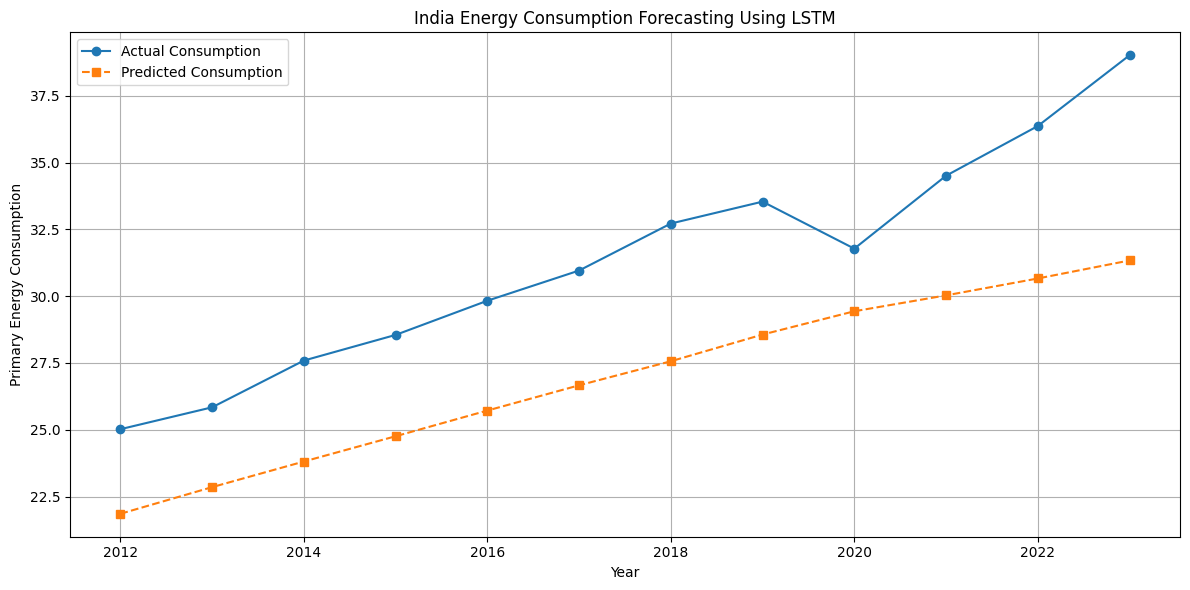

In [ ]:

plt.figure(figsize=(12, 6))

plt.plot(
    test_years,
    y_test_actual,
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    test_years,
    y_pred_actual,
    marker="s",
    linestyle="--",
    label="Predicted Consumption"
)

plt.title("India Energy Consumption Forecasting Using LSTM")
plt.xlabel("Year")
plt.ylabel("Primary Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


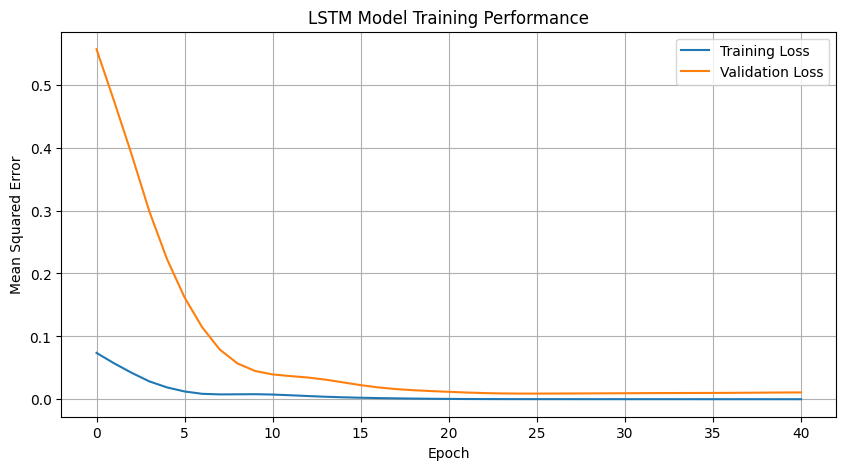

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Model Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# Use the last five observed years
last_five_years = scaled_values[-5:].reshape(1, 5, 1)

# Predict next year
next_scaled = model.predict(
    last_five_years,
    verbose=0
)

next_consumption = scaler.inverse_transform(
    next_scaled
)[0, 0]

next_year = int(data["year"].iloc[-1]) + 1

print("Selected Country:", country_name)
print("Forecast Year:", next_year)
print(
    "Predicted Energy Consumption:",
    round(float(next_consumption), 4)
)


Selected Country: India
Forecast Year: 2024
Predicted Energy Consumption: 32.0638
